<a href="https://colab.research.google.com/github/joaomigueljm16/Disciplina-Redes-Neurais/blob/main/C%C3%B3digo_Jo%C3%A3o_%20HousePrice.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
from kagglehub import KaggleDatasetAdapter
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import mean_squared_error, r2_score
from tensorflow.keras.layers import Dropout
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import (
    Adam, AdamW, SGD, RMSprop, Nadam
)

In [ ]:
pip install kagglehub[pandas-datasets]

In [ ]:
# Set the path to the file you'd like to load
file_path = "train.csv"

# Load the latest version
df = kagglehub.load_dataset(
  KaggleDatasetAdapter.PANDAS,
  "lespin/house-prices-dataset",
  file_path,
  # Provide any additional arguments like
  # sql_query or pandas_kwargs. See the
  # documenation for more information:
  # https://github.com/Kaggle/kagglehub/blob/main/README.md#kaggledatasetadapterpandas
)

print("First 5 records:", df.head(6))

/tmp/ipykernel_1953/3202925883.py:5: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df = kagglehub.load_dataset(


100%|██████████| 450k/450k [00:00<00:00, 5.09MB/s]

First 5 records: 

   Id  MSSubClass MSZoning  LotFrontage  LotArea Street Alley LotShape  \
0   1          60       RL         65.0     8450   Pave   NaN      Reg   
1   2          20       RL         80.0     9600   Pave   NaN      Reg   
2   3          60       RL         68.0    11250   Pave   NaN      IR1   
3   4          70       RL         60.0     9550   Pave   NaN      IR1   
4   5          60       RL         84.0    14260   Pave   NaN      IR1   
5   6          50       RL         85.0    14115   Pave   NaN      IR1   

  LandContour Utilities  ... PoolArea PoolQC  Fence MiscFeature MiscVal  \
0         Lvl    AllPub  ...        0    NaN    NaN         NaN       0   
1         Lvl    AllPub  ...        0    NaN    NaN         NaN       0   
2         Lvl    AllPub  ...        0    NaN    NaN         NaN       0   
3         Lvl    AllPub  ...        0    NaN    NaN         NaN       0   
4         Lvl    AllPub  ...        0    NaN    NaN         NaN       0   
5         Lvl    AllPub  ...   

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [ ]:
cols_to_drop = ['Alley', 'MasVnrType', 'FireplaceQu', 'PoolQC', 'Fence', 'MiscFeature']
df = df.drop(columns=cols_to_drop, errors='ignore')
print("Colunas restantes:", df.shape[1])
df.info()

Colunas restantes: 75
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 75 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   LotShape       1460 non-null   object 
 7   LandContour    1460 non-null   object 
 8   Utilities      1460 non-null   object 
 9   LotConfig      1460 non-null   object 
 10  LandSlope      1460 non-null   object 
 11  Neighborhood   1460 non-null   object 
 12  Condition1     1460 non-null   object 
 13  Condition2     1460 non-null   object 
 14  BldgType       1460 non-null   object 
 15  HouseStyle     1460 non-null   object 
 16  OverallQual    1460 non-null   int64  
 17  OverallCond    1460 non-null  

In [ ]:
# Preenchendo valores ausentes das colunas numéricas com a mediana de cada coluna
numeric_cols = df.select_dtypes(include=['number']).columns
df[numeric_cols] = df[numeric_cols].fillna(df[numeric_cols].median())

# Para as colunas categóricas restantes, podemos usar ffill como anteriormente
df = df.ffill()

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 75 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1460 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   LotShape       1460 non-null   object 
 7   LandContour    1460 non-null   object 
 8   Utilities      1460 non-null   object 
 9   LotConfig      1460 non-null   object 
 10  LandSlope      1460 non-null   object 
 11  Neighborhood   1460 non-null   object 
 12  Condition1     1460 non-null   object 
 13  Condition2     1460 non-null   object 
 14  BldgType       1460 non-null   object 
 15  HouseStyle     1460 non-null   object 
 16  OverallQual    1460 non-null   int64  
 17  OverallCond    1460 non-null   int64  
 18  YearBuil

In [ ]:
df.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,69.863699,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.117123,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,22.027677,9981.264932,1.382997,1.112799,30.202904,20.645407,180.731373,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,60.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,79.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,164.250000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [ ]:
# Selecionando variáveis categóricas nos dados de treinamento
cat_cols = df.select_dtypes(include=['object']).columns
df[cat_cols] = df[cat_cols].fillna(df[cat_cols].mode())

# Para as colunas categóricas restantes, podemos usar ffill como anteriormente
df = df.ffill()

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 75 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1460 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   LotShape       1460 non-null   object 
 7   LandContour    1460 non-null   object 
 8   Utilities      1460 non-null   object 
 9   LotConfig      1460 non-null   object 
 10  LandSlope      1460 non-null   object 
 11  Neighborhood   1460 non-null   object 
 12  Condition1     1460 non-null   object 
 13  Condition2     1460 non-null   object 
 14  BldgType       1460 non-null   object 
 15  HouseStyle     1460 non-null   object 
 16  OverallQual    1460 non-null   int64  
 17  OverallCond    1460 non-null   int64  
 18  YearBuil

In [ ]:
# Verificar os valores únicos antes da transformação
print("Valores originais em Street:", df['Street'].unique())

# Mapear 'Pave' para 1 e 'Grvl' para 0 (ou vice-versa)
df['Street'] = df['Street'].map({'Pave': 1, 'Grvl': 0})

# Exibir os novos valores e as primeiras linhas
print("Novos valores em Street:", df['Street'].unique())
display(df[['Street']].head())

Valores originais em Street: ['Pave' 'Grvl']
Novos valores em Street: [1 0]


,Street
0,1
1,1
2,1
3,1
4,1


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 75 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1460 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   int64  
 6   LotShape       1460 non-null   object 
 7   LandContour    1460 non-null   object 
 8   Utilities      1460 non-null   object 
 9   LotConfig      1460 non-null   object 
 10  LandSlope      1460 non-null   object 
 11  Neighborhood   1460 non-null   object 
 12  Condition1     1460 non-null   object 
 13  Condition2     1460 non-null   object 
 14  BldgType       1460 non-null   object 
 15  HouseStyle     1460 non-null   object 
 16  OverallQual    1460 non-null   int64  
 17  OverallCond    1460 non-null   int64  
 18  YearBuil

In [ ]:
# Verificar os valores únicos originais de LotShape
print("Valores originais em LotShape:", df['LotShape'].unique())

# Mapear os valores ordenados de forma que fiquem em uma escala numérica
lot_shape_map = {'Reg': 3, 'IR1': 2, 'IR2': 1, 'IR3': 0}
df['LotShape'] = df['LotShape'].map(lot_shape_map)

# Exibir os valores após a transformação
print("Novos valores em LotShape:", df['LotShape'].unique())
display(df[['LotShape']].head())

Valores originais em LotShape: ['Reg' 'IR1' 'IR2' 'IR3']
Novos valores em LotShape: [3 2 1 0]


,LotShape
0,3
1,3
2,2
3,2
4,2


In [ ]:
df.info(
)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 75 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1460 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   int64  
 6   LotShape       1460 non-null   int64  
 7   LandContour    1460 non-null   object 
 8   Utilities      1460 non-null   object 
 9   LotConfig      1460 non-null   object 
 10  LandSlope      1460 non-null   object 
 11  Neighborhood   1460 non-null   object 
 12  Condition1     1460 non-null   object 
 13  Condition2     1460 non-null   object 
 14  BldgType       1460 non-null   object 
 15  HouseStyle     1460 non-null   object 
 16  OverallQual    1460 non-null   int64  
 17  OverallCond    1460 non-null   int64  
 18  YearBuil

In [ ]:
# Verificar os valores únicos originais de Utilities
print("Valores originais em Utilities:", df['Utilities'].unique())

# Mapear os valores de Utilities de forma sequencial (ex: AllPub = 3, NoSewr = 2, NoSeWa = 1, ELO = 0)
# (Se houverem menos categorias presentes nos dados, o mapeamento ainda funcionará corretamente)
utilities_map = {'AllPub': 3, 'NoSewr': 2, 'NoSeWa': 1, 'ELO': 0}
df['Utilities'] = df['Utilities'].map(utilities_map)

# Exibir os valores após a transformação
print("Novos valores em Utilities:", df['Utilities'].unique())
display(df[['Utilities']].head())

Valores originais em Utilities: ['AllPub' 'NoSeWa']
Novos valores em Utilities: [3 1]


,Utilities
0,3
1,3
2,3
3,3
4,3


In [ ]:
df.info(

)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 75 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1460 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   int64  
 6   LotShape       1460 non-null   int64  
 7   LandContour    1460 non-null   object 
 8   Utilities      1460 non-null   int64  
 9   LotConfig      1460 non-null   object 
 10  LandSlope      1460 non-null   object 
 11  Neighborhood   1460 non-null   object 
 12  Condition1     1460 non-null   object 
 13  Condition2     1460 non-null   object 
 14  BldgType       1460 non-null   object 
 15  HouseStyle     1460 non-null   object 
 16  OverallQual    1460 non-null   int64  
 17  OverallCond    1460 non-null   int64  
 18  YearBuil

In [ ]:
# Verificar os valores únicos originais de LandSlope
print("Valores originais em LandSlope:", df['LandSlope'].unique())

# Mapear os valores de LandSlope de forma sequencial (Gtl = 0, Mod = 1, Sev = 2)
landslope_map = {'Gtl': 0, 'Mod': 1, 'Sev': 2}
df['LandSlope'] = df['LandSlope'].map(landslope_map)

# Exibir os valores após a transformação
print("Novos valores em LandSlope:", df['LandSlope'].unique())
display(df[['LandSlope']].head())

Valores originais em LandSlope: ['Gtl' 'Mod' 'Sev']
Novos valores em LandSlope: [0 1 2]


,LandSlope
0,0
1,0
2,0
3,0
4,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 75 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1460 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   int64  
 6   LotShape       1460 non-null   int64  
 7   LandContour    1460 non-null   object 
 8   Utilities      1460 non-null   int64  
 9   LotConfig      1460 non-null   object 
 10  LandSlope      1460 non-null   int64  
 11  Neighborhood   1460 non-null   object 
 12  Condition1     1460 non-null   object 
 13  Condition2     1460 non-null   object 
 14  BldgType       1460 non-null   object 
 15  HouseStyle     1460 non-null   object 
 16  OverallQual    1460 non-null   int64  
 17  OverallCond    1460 non-null   int64  
 18  YearBuil

In [ ]:
# 1. Recarregar o dataset limpo
df = kagglehub.load_dataset(
  KaggleDatasetAdapter.PANDAS,
  "lespin/house-prices-dataset",
  "train.csv"
)

# 2. Descartar as colunas com muitos valores nulos
cols_to_drop = ['Alley', 'MasVnrType', 'FireplaceQu', 'PoolQC', 'Fence', 'MiscFeature']
df = df.drop(columns=cols_to_drop, errors='ignore')

# 3. Tratar valores ausentes
numeric_cols = df.select_dtypes(include=['number']).columns
df[numeric_cols] = df[numeric_cols].fillna(df[numeric_cols].median())
df = df.ffill()

# 4. Aplicar as transformações anteriores de forma limpa
df['Street'] = df['Street'].map({'Pave': 1, 'Grvl': 0})
df['LotShape'] = df['LotShape'].map({'Reg': 3, 'IR1': 2, 'IR2': 1, 'IR3': 0})
df['Utilities'] = df['Utilities'].map({'AllPub': 3, 'NoSewr': 2, 'NoSeWa': 1, 'ELO': 0})
df['LandSlope'] = df['LandSlope'].map({'Gtl': 0, 'Mod': 1, 'Sev': 2})

# 5. Aplicar o mapeamento correto em ExterQual
print("Valores originais em ExterQual:", df['ExterQual'].unique())
df['ExterQual'] = df['ExterQual'].map({'Ex': 4, 'Gd': 3, 'TA': 2, 'Fa': 1, 'Po': 0})
print("Novos valores em ExterQual:", df['ExterQual'].unique())

df.info()

/tmp/ipykernel_1953/1399943189.py:2: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df = kagglehub.load_dataset(


Valores originais em ExterQual: ['Gd' 'TA' 'Ex' 'Fa']
Novos valores em ExterQual: [3 2 4 1]
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 75 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1460 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   int64  
 6   LotShape       1460 non-null   int64  
 7   LandContour    1460 non-null   object 
 8   Utilities      1460 non-null   int64  
 9   LotConfig      1460 non-null   object 
 10  LandSlope      1460 non-null   int64  
 11  Neighborhood   1460 non-null   object 
 12  Condition1     1460 non-null   object 
 13  Condition2     1460 non-null   object 
 14  BldgType       1460 non-null   object 
 15  HouseStyle     1460 non-null   object 
 16  Over

In [ ]:
# Mapear os valores de ExterCond de forma sequencial (Po = 0, Fa = 1, TA = 2, Gd= 3, Ex=4)
df['ExterCond'] = df['ExterCond'].map({'Po': 0, 'Fa': 1, 'TA': 2, 'Gd': 3, 'Ex': 4})

# Exibir os valores após a transformação
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 75 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1460 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   int64  
 6   LotShape       1460 non-null   int64  
 7   LandContour    1460 non-null   object 
 8   Utilities      1460 non-null   int64  
 9   LotConfig      1460 non-null   object 
 10  LandSlope      1460 non-null   int64  
 11  Neighborhood   1460 non-null   object 
 12  Condition1     1460 non-null   object 
 13  Condition2     1460 non-null   object 
 14  BldgType       1460 non-null   object 
 15  HouseStyle     1460 non-null   object 
 16  OverallQual    1460 non-null   int64  
 17  OverallCond    1460 non-null   int64  
 18  YearBuil

In [ ]:
# # Mapear os valores de BsmtQual de forma sequencial (NA = 0, Po = 1, Fa = 2, TA= 3, Gd=4, Ex=5)
df['BsmtQual'] = df['BsmtQual'].map({'NA': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5})


# Exibir os valores após a transformação
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 75 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1460 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   int64  
 6   LotShape       1460 non-null   int64  
 7   LandContour    1460 non-null   object 
 8   Utilities      1460 non-null   int64  
 9   LotConfig      1460 non-null   object 
 10  LandSlope      1460 non-null   int64  
 11  Neighborhood   1460 non-null   object 
 12  Condition1     1460 non-null   object 
 13  Condition2     1460 non-null   object 
 14  BldgType       1460 non-null   object 
 15  HouseStyle     1460 non-null   object 
 16  OverallQual    1460 non-null   int64  
 17  OverallCond    1460 non-null   int64  
 18  YearBuil

In [ ]:
# # Mapear os valores de BsmtCond de forma sequencial (NA = 0, Po = 1, Fa = 2, TA= 3, Gd=4, Ex=5)
df['BsmtCond'] = df['BsmtCond'].map({'NA': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5})



In [ ]:
 # Mapear os valores de BsmtExposure de forma sequencial (NA = 0, No = 1, Mn = 2, Av= 3, Gd=4)
 df["BsmtExposure"] = df["BsmtExposure"].map({'NA': 0, 'No': 1, 'Mn': 2, 'Av': 3, 'Gd': 4})

 df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 75 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1460 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   int64  
 6   LotShape       1460 non-null   int64  
 7   LandContour    1460 non-null   object 
 8   Utilities      1460 non-null   int64  
 9   LotConfig      1460 non-null   object 
 10  LandSlope      1460 non-null   int64  
 11  Neighborhood   1460 non-null   object 
 12  Condition1     1460 non-null   object 
 13  Condition2     1460 non-null   object 
 14  BldgType       1460 non-null   object 
 15  HouseStyle     1460 non-null   object 
 16  OverallQual    1460 non-null   int64  
 17  OverallCond    1460 non-null   int64  
 18  YearBuil

In [ ]:
# Mapear os valores de BsmtFinType1 de forma sequencial (NA = 0, Unf = 1, LwQ = 2, Rec= 3, BLQ= 4, ALQ= 5, GLQ= 6)
df["BsmtFinType1"] = df["BsmtFinType1"].map({'NA': 0, 'Unf': 1, 'LwQ': 2, 'Rec': 3, 'BLQ': 4, 'ALQ': 5, 'GLQ': 6})


In [ ]:
# Mapear os valores de BsmtFinType2 de forma sequencial (NA = 0, Unf = 1, LwQ = 2, Rec= 3, BLQ= 4, ALQ= 5, GLQ= 6)
df["BsmtFinType2"] = df["BsmtFinType2"].map({'NA': 0, 'Unf': 1, 'LwQ': 2, 'Rec': 3, 'BLQ': 4, 'ALQ':5,'GLQ': 6})

In [ ]:
# Mapear os valores de HeatingQC de forma sequencial (Po = 0, Fa = 1, TA = 2, Gd= 3, Ex= 4)
df["HeatingQC"]= df["HeatingQC"].map({'Po': 0, 'Fa': 1, 'TA': 2, 'Gd': 3, 'Ex': 4})

In [ ]:
# Mapear os valores de CentralAir de forma binária (N = 0, Y = 1)
df["CentralAir"] = df["CentralAir"].map({'N': 0, 'Y': 1})

In [ ]:
# Mapear os valores de KitchenQual de forma sequencial (Po = 0, Fa = 1, TA = 2, Gd= 3, Ex= 4)
df["KitchenQual"] = df["KitchenQual"].map({'Po': 0, 'Fa': 1, 'TA': 2, 'Gd': 3, 'Ex': 4})


In [ ]:
# Mapear os valores de GarageFinish de forma sequencial (NA = 0, Unf = 1, RFn = 2, Fin= 3)
df["GarageFinish"] = df["GarageFinish"].map({'NA': 0, 'Unf': 1, 'RFn': 2, 'Fin': 3})


In [ ]:
# Mapear os valores de GarageQual de forma sequencial (NA = 0, Po = 1, Fa = 2, TA = 3, Gd= 4, Ex= 5)
df["GarageQual"] = df["GarageQual"].map({'NA': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5})


In [ ]:
# Mapear os valores de GarageCond de forma sequencial (NA = 0, Po = 1, Fa = 2, TA = 3, Gd= 4, Ex= 5)
df["GarageCond"] = df["GarageCond"].map({'NA': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5})


In [ ]:
# Transformando variáveis categóricas em variáveis dummies (binárias)
df = pd.get_dummies(df)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Columns: 217 entries, Id to SaleCondition_Partial
dtypes: bool(162), float64(3), int64(52)
memory usage: 858.4 KB


In [ ]:
#Separando variáveis preditoras (x) da variável alvo (y)
x = df.drop(columns=['SalePrice', "Id"])
y = df['SalePrice']

#Escalonamento das variáveis
scaler = StandardScaler()
x_scaled = scaler.fit_transform(x)

Preparando dados de teste/validação

In [ ]:
# Set the path to the file you'd like to load
file_path = "test.csv"

# Load the latest version
df_test = kagglehub.load_dataset(
  KaggleDatasetAdapter.PANDAS,
  "lespin/house-prices-dataset",
  file_path,
  # Provide any additional arguments like
  # sql_query or pandas_kwargs. See the
  # documenation for more information:
  # https://github.com/Kaggle/kagglehub/blob/main/README.md#kaggledatasetadapterpandas
)

/tmp/ipykernel_1953/1409515494.py:5: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df_test = kagglehub.load_dataset(


100%|██████████| 441k/441k [00:00<00:00, 5.06MB/s]


In [ ]:
cols_to_drop = ['Alley', 'MasVnrType', 'FireplaceQu', 'PoolQC', 'Fence', 'MiscFeature']
df_test = df_test.drop(columns=cols_to_drop, errors='ignore')
print("Colunas restantes:", df_test.shape[1])
df_test.info()

Colunas restantes: 74
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1459 entries, 0 to 1458
Data columns (total 74 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1459 non-null   int64  
 1   MSSubClass     1459 non-null   int64  
 2   MSZoning       1455 non-null   object 
 3   LotFrontage    1232 non-null   float64
 4   LotArea        1459 non-null   int64  
 5   Street         1459 non-null   object 
 6   LotShape       1459 non-null   object 
 7   LandContour    1459 non-null   object 
 8   Utilities      1457 non-null   object 
 9   LotConfig      1459 non-null   object 
 10  LandSlope      1459 non-null   object 
 11  Neighborhood   1459 non-null   object 
 12  Condition1     1459 non-null   object 
 13  Condition2     1459 non-null   object 
 14  BldgType       1459 non-null   object 
 15  HouseStyle     1459 non-null   object 
 16  OverallQual    1459 non-null   int64  
 17  OverallCond    1459 non-null  

In [ ]:
# Preenchendo valores ausentes das colunas numéricas com a mediana de cada coluna
numeric_cols_b = df_test.select_dtypes(include=['number']).columns
df_test[numeric_cols_b] = df_test[numeric_cols_b].fillna(df_test[numeric_cols_b].median())

# Para as colunas categóricas restantes, podemos usar ffill como anteriormente
df_test = df_test.ffill()

df_test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1459 entries, 0 to 1458
Data columns (total 74 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1459 non-null   int64  
 1   MSSubClass     1459 non-null   int64  
 2   MSZoning       1459 non-null   object 
 3   LotFrontage    1459 non-null   float64
 4   LotArea        1459 non-null   int64  
 5   Street         1459 non-null   object 
 6   LotShape       1459 non-null   object 
 7   LandContour    1459 non-null   object 
 8   Utilities      1459 non-null   object 
 9   LotConfig      1459 non-null   object 
 10  LandSlope      1459 non-null   object 
 11  Neighborhood   1459 non-null   object 
 12  Condition1     1459 non-null   object 
 13  Condition2     1459 non-null   object 
 14  BldgType       1459 non-null   object 
 15  HouseStyle     1459 non-null   object 
 16  OverallQual    1459 non-null   int64  
 17  OverallCond    1459 non-null   int64  
 18  YearBuil

In [ ]:
# Selecionando variáveis categóricas nos dados de treinamento
cat_cols_b = df_test.select_dtypes(include=['object']).columns
df_test[cat_cols_b] = df_test[cat_cols_b].fillna(df_test[cat_cols_b].mode())

# Para as colunas categóricas restantes, podemos usar ffill como anteriormente
df_test = df_test.ffill()

In [ ]:
# Aplicar padronização de variaveis
df_test['Street'] = df_test['Street'].map({'Pave': 1, 'Grvl': 0})
df_test['LotShape'] = df_test['LotShape'].map({'Reg': 3, 'IR1': 2, 'IR2': 1, 'IR3': 0})
df_test['Utilities'] = df_test['Utilities'].map({'AllPub': 3, 'NoSewr': 2, 'NoSeWa': 1, 'ELO': 0})
df_test['LandSlope'] = df_test['LandSlope'].map({'Gtl': 0, 'Mod': 1, 'Sev': 2})

In [ ]:
df_test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1459 entries, 0 to 1458
Data columns (total 74 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1459 non-null   int64  
 1   MSSubClass     1459 non-null   int64  
 2   MSZoning       1459 non-null   object 
 3   LotFrontage    1459 non-null   float64
 4   LotArea        1459 non-null   int64  
 5   Street         1459 non-null   int64  
 6   LotShape       1459 non-null   int64  
 7   LandContour    1459 non-null   object 
 8   Utilities      1459 non-null   int64  
 9   LotConfig      1459 non-null   object 
 10  LandSlope      1459 non-null   int64  
 11  Neighborhood   1459 non-null   object 
 12  Condition1     1459 non-null   object 
 13  Condition2     1459 non-null   object 
 14  BldgType       1459 non-null   object 
 15  HouseStyle     1459 non-null   object 
 16  OverallQual    1459 non-null   int64  
 17  OverallCond    1459 non-null   int64  
 18  YearBuil

In [ ]:
# Mapear os valores de ExterCond de forma sequencial (Po = 0, Fa = 1, TA = 2, Gd= 3, Ex=4)
df_test['ExterCond'] = df_test['ExterCond'].map({'Po': 0, 'Fa': 1, 'TA': 2, 'Gd': 3, 'Ex': 4})
# Mapear os valores de BsmtQual de forma sequencial (NA = 0, Po = 1, Fa = 2, TA= 3, Gd=4, Ex=5)
df_test['BsmtQual'] = df_test['BsmtQual'].map({'NA': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5})
# Mapear os valores de BsmtCond de forma sequencial (NA = 0, Po = 1, Fa = 2, TA= 3, Gd=4, Ex=5)
df_test['BsmtCond'] = df_test['BsmtCond'].map({'NA': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5})
# Mapear os valores de BsmtExposure de forma sequencial (NA = 0, No = 1, Mn = 2, Av= 3, Gd=4)
df_test["BsmtExposure"] = df_test["BsmtExposure"].map({'NA': 0, 'No': 1, 'Mn': 2, 'Av': 3, 'Gd': 4})
# Mapear os valores de BsmtFinType1 de forma sequencial (NA = 0, Unf = 1, LwQ = 2, Rec= 3, BLQ= 4, ALQ= 5, GLQ= 6)
df_test["BsmtFinType1"] = df_test["BsmtFinType1"].map({'NA': 0, 'Unf': 1, 'LwQ': 2, 'Rec': 3, 'BLQ': 4, 'ALQ': 5, 'GLQ': 6})
# Mapear os valores de BsmtFinType2 de forma sequencial (NA = 0, Unf = 1, LwQ = 2, Rec= 3, BLQ= 4, ALQ= 5, GLQ= 6)
df_test["BsmtFinType2"] = df_test["BsmtFinType2"].map({'NA': 0, 'Unf': 1, 'LwQ': 2, 'Rec': 3, 'BLQ': 4, 'ALQ': 5, 'GLQ': 6})
# Mapear os valores de HeatingQC de forma sequencial (Po = 0, Fa = 1, TA = 2, Gd= 3, Ex= 4)
df_test["HeatingQC"] = df_test["HeatingQC"].map({'Po': 0, 'Fa': 1, 'TA': 2, 'Gd': 3, 'Ex': 4})
# Mapear os valores de CentralAir de forma binária (N = 0, Y = 1)
df_test["CentralAir"] = df_test["CentralAir"].map({'N': 0, 'Y': 1})
# Mapear os valores de KitchenQual de forma sequencial (Po = 0, Fa = 1, TA = 2, Gd= 3, Ex= 4)
df_test["KitchenQual"] = df_test["KitchenQual"].map({'Po': 0, 'Fa': 1, 'TA': 2, 'Gd': 3, 'Ex': 4})
# Mapear os valores de GarageFinish de forma sequencial (NA = 0, Unf = 1, RFn = 2, Fin= 3)
df_test["GarageFinish"] = df_test["GarageFinish"].map({'NA': 0, 'Unf': 1, 'RFn': 2, 'Fin': 3})
# Mapear os valores de GarageQual de forma sequencial (NA = 0, Po = 1, Fa = 2, TA = 3, Gd= 4, Ex= 5)
df_test["GarageQual"] = df_test["GarageQual"].map({'NA': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5})
# Mapear os valores de GarageCond de forma sequencial (NA = 0, Po = 1, Fa = 2, TA = 3, Gd= 4, Ex= 5)
df_test["GarageCond"] = df_test["GarageCond"].map({'NA': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5})

In [ ]:
# Transformando variáveis categóricas em variáveis dummies (binárias)
df_test = pd.get_dummies(df_test)
df_test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1459 entries, 0 to 1458
Columns: 205 entries, Id to SaleCondition_Partial
dtypes: bool(152), float64(11), int64(42)
memory usage: 820.8 KB


In [ ]:
# Transformando variáveis categóricas do conjunto de teste em variáveis dummies
df_test_dummies = pd.get_dummies(df_test)

# Separando as variáveis preditoras (removendo a coluna de identificação 'Id')
x_t = df_test_dummies.drop(columns=["Id"], errors='ignore')

# Garantindo que o conjunto de teste tenha exatamente as mesmas colunas que o de treino (x)
# Preenchemos com 0 colunas que existam no treino mas não existam no teste
x_t = x_t.reindex(columns=x.columns, fill_value=0)

# Escalonamento das variáveis de teste usando o scaler já criado
scaler = StandardScaler()
x_test_scaled = scaler.fit_transform(x_t)

print("Dados de teste preparados e escalonados com sucesso!")

Dados de teste preparados e escalonados com sucesso!


Finalizando a divisão de treinamento e teste (train, test split)

In [ ]:
# Divisão dos dados de treino em treino e validação usando train_test_split corretamente importado
x_train, x_test, y_train, y_test = train_test_split(x_scaled, y, test_size=0.20, random_state=42)

print("Divisão de treino e validação concluída com sucesso!")
print(f"Treino: {x_train.shape[0]} amostras | Validação: {x_test.shape[0]} amostras")


Divisão de treino e validação concluída com sucesso!
Treino: 1168 amostras | Validação: 292 amostras


**Arquitetura e treinamento da Rede Neural**

In [ ]:
# Criar a arquitetura do modelo
model = Sequential([
    Dense(110, activation='relu', input_shape=(x_train.shape[1],)),
    Dense(55, activation='relu'),
    Dense(1, activation='linear')  # Camada de saída para regressão
])

# Compilar o modelo
model.compile(optimizer=Adam(learning_rate=0.005), loss='mean_squared_error', metrics=['mae'])

# Treinar o modelo
history = model.fit(x_train, y_train, epochs=100, batch_size=32,
                    validation_split=0.2, verbose=1)

Epoch 1/100


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


30/30 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - loss: 39121149952.0000 - mae: 181469.0469 - val_loss: 37735202816.0000 - val_mae: 180869.3438
Epoch 2/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 38667980800.0000 - mae: 180526.6094 - val_loss: 36738809856.0000 - val_mae: 178724.4688
Epoch 3/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 36460863488.0000 - mae: 175838.8594 - val_loss: 33170536448.0000 - val_mae: 170733.9531
Epoch 4/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 30875668480.0000 - mae: 162759.0469 - val_loss: 25829574656.0000 - val_mae: 152105.9844
Epoch 5/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 21758953472.0000 - mae: 137308.2344 - val_loss: 16670189568.0000 - val_mae: 121528.7969
Epoch 6/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 12514650112.0000 - mae: 101327.4141 - val_loss: 10018573312.0000 - val_mae: 85970.2812
Epoch 7/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 7578781696.0000 - mae: 71973.2578 - val_loss: 7335451136.0000 - val_m

**Validação do modelo**

In [ ]:
# Avaliação do desempenho do modelo no conjunto de teste
loss, mae = model.evaluate(x_test, y_test, verbose=0)
y_pred = model.predict(x_test)

#métricas extras de avaliação
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"Perda no conjunto de teste: {loss:.4f}")
print(f"Erro médio absoluto no conjunto de teste: {mae:.4f}")
print(f"Erro quadrático médio (MSE) no conjunto de teste: {mse:.4f}")
print(f"Raiz do erro quadrático médio (RMSE) no conjunto de teste: {rmse:.4}")
print(f"Coeficiente de determinação (R²): {r2:.4f}")

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
Perda no conjunto de teste: 1574803072.0000
Erro médio absoluto no conjunto de teste: 23706.1641
Erro quadrático médio (MSE) no conjunto de teste: 1574802944.0000
Raiz do erro quadrático médio (RMSE) no conjunto de teste: 3.968e+04
Coeficiente de determinação (R²): 0.7947


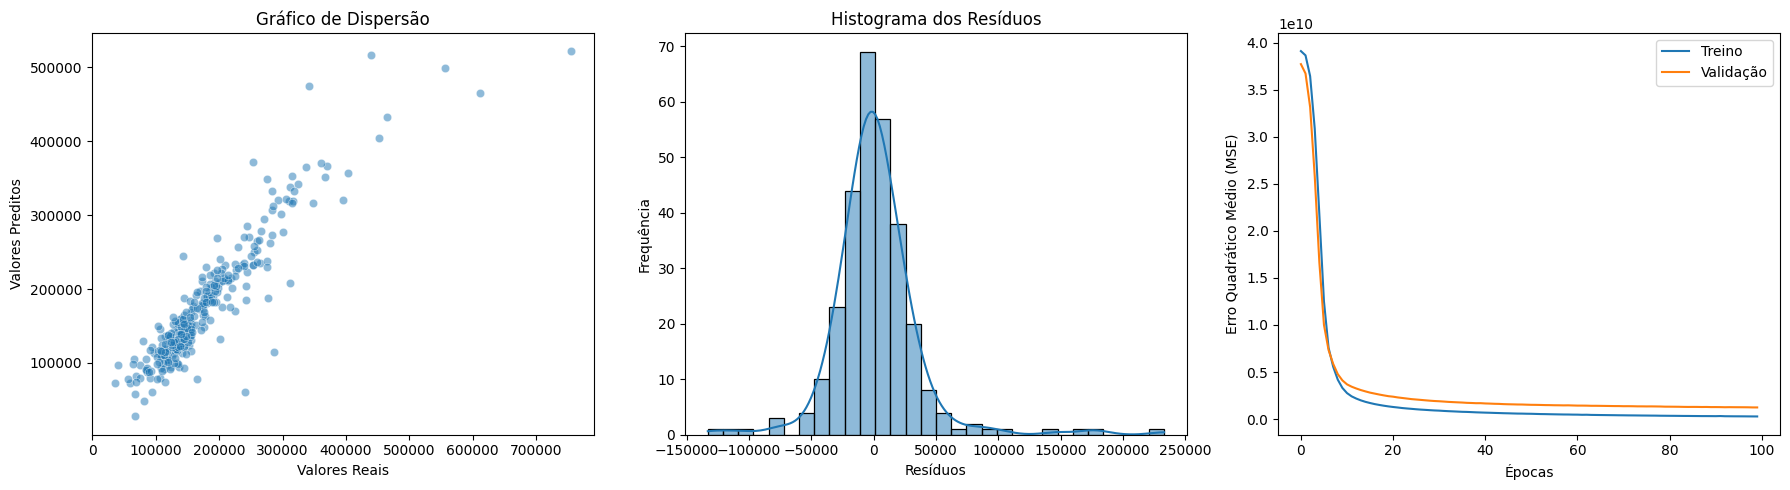

In [ ]:
# Comparação entre valores reais e preditos dos preços dos imóveis
plt.figure(figsize=(18, 5))

# Achatar y_pred para 1 dimensão para evitar erro no Seaborn/Pandas
y_pred_flat = y_pred.flatten()

# Gráfico de dispersão
plt.subplot(1, 3, 1)
sns.scatterplot(x=y_test, y=y_pred_flat, alpha=0.5)
plt.xlabel('Valores Reais')
plt.ylabel('Valores Preditos')
plt.title('Gráfico de Dispersão')

# Resíduos
plt.subplot(1, 3, 2)
residuals = y_test - y_pred_flat
sns.histplot(residuals, kde=True, bins=30)
plt.xlabel('Resíduos')
plt.ylabel('Frequência')
plt.title('Histograma dos Resíduos')

# Curva de perda / Função de perda
plt.subplot(1, 3, 3)
plt.plot(history.history['loss'], label='Treino')
plt.plot(history.history['val_loss'], label='Validação')
plt.xlabel('Épocas')
plt.ylabel('Erro Quadrático Médio (MSE)')
plt.legend()

plt.tight_layout()
plt.show()

**Otimização e Regularização da Rede Neural**

In [ ]:
model_b = Sequential([
    Dense(140, activation='relu', input_shape=(x_train.shape[1],)),
    Dropout(0.3),
    Dense(70, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='linear')
])

# Compilar o modelo
model_b.compile(optimizer= RMSprop(learning_rate=0.02), loss='mean_squared_error', metrics=['mae'])

#EarlyStopping
early_stopping = EarlyStopping(monitor='val_loss', patience=35, restore_best_weights=True)

# Treinar o modelo
history_b = model_b.fit(x_train, y_train, epochs=300, batch_size=40,
                    validation_split=0.2, callbacks=[early_stopping], verbose=1)

# Avaliação do desempenho do modelo no conjunto de teste
loss, mae = model_b.evaluate(x_test, y_test, verbose=0)
y_pred = model_b.predict(x_test)

#métricas extras de avaliação
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"Perda no conjunto de teste: {loss:.4f}")
print(f"Erro médio absoluto no conjunto de teste: {mae:.4f}")
print(f"Erro quadrático médio (MSE) no conjunto de teste: {mse:.4f}")
print(f"Raiz do erro quadrático médio (RMSE) no conjunto de teste: {rmse:.4f}")
print(f"Coeficiente de determinação (R²): {r2:.4f}")

Epoch 1/300


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 34330394624.0000 - mae: 169992.0312 - val_loss: 22861703168.0000 - val_mae: 141168.3750
Epoch 2/300
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 13875828736.0000 - mae: 102230.6406 - val_loss: 6730514944.0000 - val_mae: 61761.6250
Epoch 3/300
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 5349835264.0000 - mae: 53117.0312 - val_loss: 4641231872.0000 - val_mae: 46369.1172
Epoch 4/300
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 4238733824.0000 - mae: 46315.4023 - val_loss: 3988813312.0000 - val_mae: 43370.8281
Epoch 5/300
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 3713814272.0000 - mae: 43439.3164 - val_loss: 3494696960.0000 - val_mae: 39385.1094
Epoch 6/300
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 3105128192.0000 - mae: 38315.0352 - val_loss: 3178469888.0000 - val_mae: 37735.7383
Epoch 7/300
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 3086560512.0000 - mae: 38860.7812 - val_loss: 2897817856.0000 - val_mae: 34638.8203
Epoc

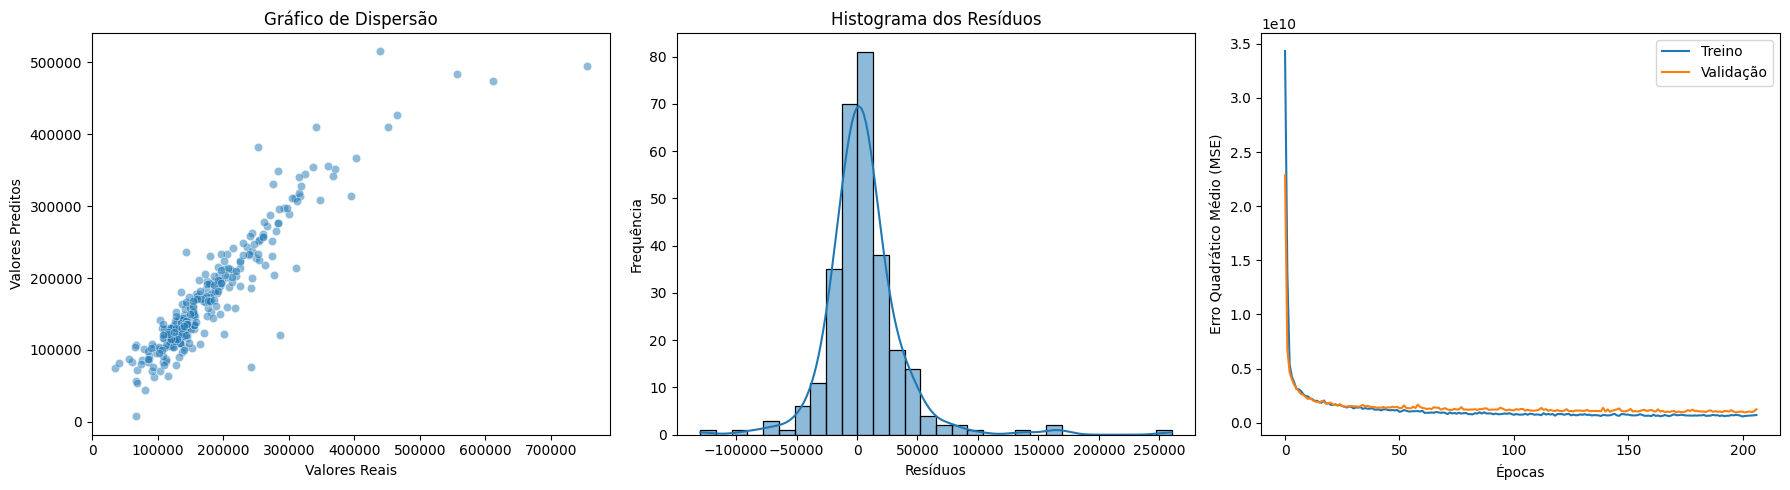

In [ ]:
# Comparação entre valores reais e preditos dos preços dos imóveis
plt.figure(figsize=(18, 5))

# Achatar y_pred para 1 dimensão para evitar erro no Seaborn/Pandas
y_pred_flat = y_pred.flatten()


# Gráfico de dispersão
plt.subplot(1, 3, 1)
sns.scatterplot(x=y_test, y=y_pred_flat, alpha=0.5)
plt.xlabel('Valores Reais')
plt.ylabel('Valores Preditos')
plt.title('Gráfico de Dispersão')




# Resíduos
plt.subplot(1, 3, 2)
residuals = y_test - y_pred_flat
sns.histplot(residuals, kde=True, bins=30)
plt.xlabel('Resíduos')
plt.ylabel('Frequência')
plt.title('Histograma dos Resíduos')

# Curva de perda / Função de perda
plt.subplot(1, 3, 3)
plt.plot(history_b.history['loss'], label='Treino')
plt.plot(history_b.history['val_loss'], label='Validação')
plt.xlabel('Épocas')
plt.ylabel('Erro Quadrático Médio (MSE)')
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
# 1. Engenharia de Features: Criar área total antes de remover/escalar variáveis
# Recarregando dados para garantir integridade caso necessário
df_eng = df.copy()
if '1stFlrSF' in df_eng.columns and '2ndFlrSF' in df_eng.columns and 'TotalBsmtSF' in df_eng.columns:
    df_eng['TotalSF'] = df_eng['1stFlrSF'] + df_eng['2ndFlrSF'] + df_eng['TotalBsmtSF']

# 2. Separar variáveis e aplicar escala Log na variável alvo
x_eng = df_eng.drop(columns=['SalePrice', 'Id'], errors='ignore')
y_log = np.log1p(df_eng['SalePrice']) # log(1 + x) para estabilidade numérica

# Escalonamento dos previsores
scaler_eng = StandardScaler()
x_eng_scaled = scaler_eng.fit_transform(x_eng)

# Split treino/validação
x_train_eng, x_test_eng, y_train_log, y_test_log = train_test_split(
    x_eng_scaled, y_log, test_size=0.20, random_state=42
)

# 3. Arquitetura refinada com taxa de aprendizado menor (mais estável)
model_optimized = Sequential([
    Dense(128, activation='relu', input_shape=(x_train_eng.shape[1],)),
    Dropout(0.3),
    Dense(64, activation='relu'),
    Dropout(0.3),
     Dense(1, activation='linear')
])

# Usando taxa de aprendizado menor para estabilizar a perda em escala de log
model_optimized.compile(optimizer=Adam(learning_rate=0.05), loss='mean_squared_error', metrics=['mae'])

# Early stopping monitorando val_loss
early_stopping_eng = EarlyStopping(monitor='val_loss', patience=25, restore_best_weights=True)

history_opt = model_optimized.fit(
    x_train_eng, y_train_log,
    epochs=250,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stopping_eng],
    verbose=1
)

Epoch 1/250


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 36.9997 - mae: 4.7486 - val_loss: 9.0511 - val_mae: 2.4423
Epoch 2/250
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 16.3902 - mae: 3.2674 - val_loss: 7.7292 - val_mae: 2.2684
Epoch 3/250
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 11.1717 - mae: 2.7068 - val_loss: 6.6088 - val_mae: 2.0943
Epoch 4/250
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 11.1863 - mae: 2.6641 - val_loss: 3.5969 - val_mae: 1.4581
Epoch 5/250
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 9.7002 - mae: 2.4527 - val_loss: 6.3024 - val_mae: 2.0947
Epoch 6/250
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 9.6257 - mae: 2.4945 - val_loss: 4.4232 - val_mae: 1.5845
Epoch 7/250
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 10.5839 - mae: 2.5857 - val_loss: 3.5816 - val_mae: 1.5344
Epoch 8/250
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 8.0933 - mae: 2.3019 - val_loss: 4.6455 - val_mae: 1.7696
Epoch 9/250
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 7.5291 - ma

In [ ]:
from sklearn.metrics import mean_absolute_error

# 4. Predição e reversão da escala logarítmica usando expm1
y_pred_log = model_optimized.predict(x_test_eng).flatten()
y_pred_original = np.expm1(y_pred_log) # Voltar para a escala em dólares
y_test_original = np.expm1(y_test_log) # Valores reais originais de teste

# Métricas finais de avaliação
mse_opt = mean_squared_error(y_test_original, y_pred_original)
mae_opt = mean_absolute_error(y_test_original, y_pred_original)
rmse_opt = np.sqrt(mse_opt)
r2_opt = r2_score(y_test_original, y_pred_original)

print("=== Métricas do Modelo Otimizado com Escala Logarítmica ===")
print(f"Erro Médio Absoluto (MAE): $ {mae_opt:.2f}")
print(f"Raiz do erro quadrático médio (RMSE): $ {rmse_opt:.2f}")
print(f"Novo Coeficiente de determinação (R²): {r2_opt:.4f}")

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 
=== Métricas do Modelo Otimizado com Escala Logarítmica ===
Erro Médio Absoluto (MAE): $ 18989.94
Raiz do erro quadrático médio (RMSE): $ 33081.84
Novo Coeficiente de determinação (R²): 0.8573


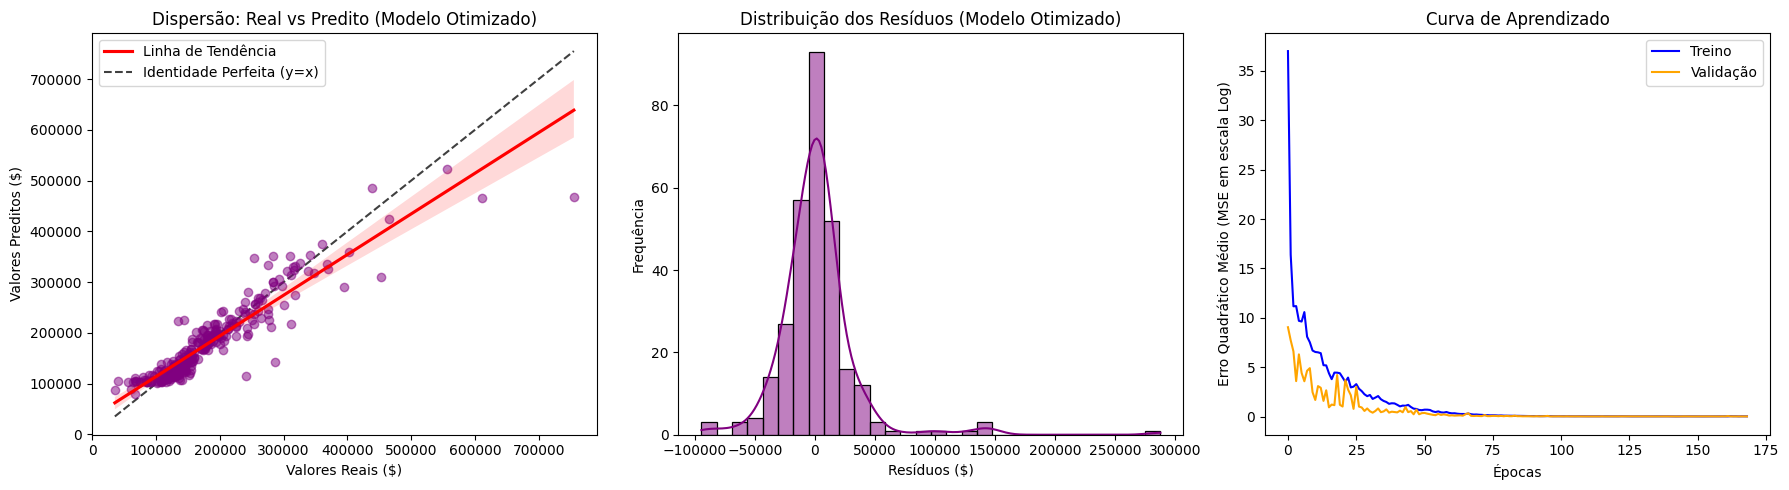

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Criar a figura para diagnóstico do modelo otimizado
plt.figure(figsize=(18, 5))

# 1. Gráfico de dispersão (Valores Reais vs Preditos com Linha de Tendência)
plt.subplot(1, 3, 1)
sns.regplot(x=y_test_original, y=y_pred_original, color='purple',
            scatter_kws={'alpha': 0.5}, line_kws={'color': 'red', 'label': 'Linha de Tendência'})

# Linha de identidade (perfeição - onde o predito é igual ao real)
lims = [np.min([y_test_original.min(), y_pred_original.min()]),
        np.max([y_test_original.max(), y_pred_original.max()])]
plt.plot(lims, lims, 'k--', alpha=0.75, zorder=0, label='Identidade Perfeita (y=x)')

plt.xlabel('Valores Reais ($)')
plt.ylabel('Valores Preditos ($)')
plt.title('Dispersão: Real vs Predito (Modelo Otimizado)')
plt.legend()

# 2. Histograma dos Resíduos
plt.subplot(1, 3, 2)
residuals_opt = y_test_original - y_pred_original
sns.histplot(residuals_opt, kde=True, bins=30, color='purple')
plt.xlabel('Resíduos ($)')
plt.ylabel('Frequência')
plt.title('Distribuição dos Resíduos (Modelo Otimizado)')

# 3. Curva de Aprendizado (Loss de Treino e Validação)
plt.subplot(1, 3, 3)
plt.plot(history_opt.history['loss'], label='Treino', color='blue')
plt.plot(history_opt.history['val_loss'], label='Validação', color='orange')
plt.xlabel('Épocas')
plt.ylabel('Erro Quadrático Médio (MSE em escala Log)')
plt.title('Curva de Aprendizado')
plt.legend()

plt.tight_layout()
plt.show()